# Practica 4: Evaluación de clustering
En esta practica trabajaremos con metricas externas para evaluar la calidad de clustering: Homogeneidad, completitud y v-measure.
Usaremos datos con etiquetas reales para poder comparar con los clusters encontrados por los modelos.

In [43]:
#bibliotecas
import sklearn
import matplotlib.pyplot as plt
import numpy as np

### **Notación**:
Dados $C={ C_1,..., C_n }$ clases reales y $K = {K_1, ..., K_m}$ clusteres encontrados, se define lo siguiente.

$H(C)$: Entropia de las clases

$H(K)$: Entropia de los clusteres

$H(C|K)$: Entropia de las clases dado que se conocen los clusteres (y viceversa)

$MI(C, K) = H(C) - H(C|K) $: Informacion mutua entre las clases reales y los clusteres encontrados



## **Homogeneidad**
Es la metrica que nos dice si en cada cluster tenemos datos de la misma clase real.

$$h =  1 - \frac{H(C|K)}{H(C)}$$


## **Completitud**
Nos dice si todos los elementos de una clase real terminaron en un mismo cluster.
$$c = 1 - \frac{H(K|C)}{H(K)}$$

La diferencia entre h y c es que no miden de forma conjunta, por ejemplo: si tenemos 2 clases reales y 6 clusteres donde en cada cluster tenemos elementos de la misma clase entonces tendremos buena homogeneidad pero mala completitud. Por ellos se considera el V-measure

## **V-measure**
Es la media armonica entre la homogeneidad y completitud. Con ello exigimos un equilibrio.
$$V = \frac{2hc}{h+c}$$


# Generacion de datos etiquetados y bien distribuidos

In [44]:
#generamos datos con etiquetas reales (3)
X, y = sklearn.datasets.make_blobs(n_samples=1500, n_features=2, centers=3)

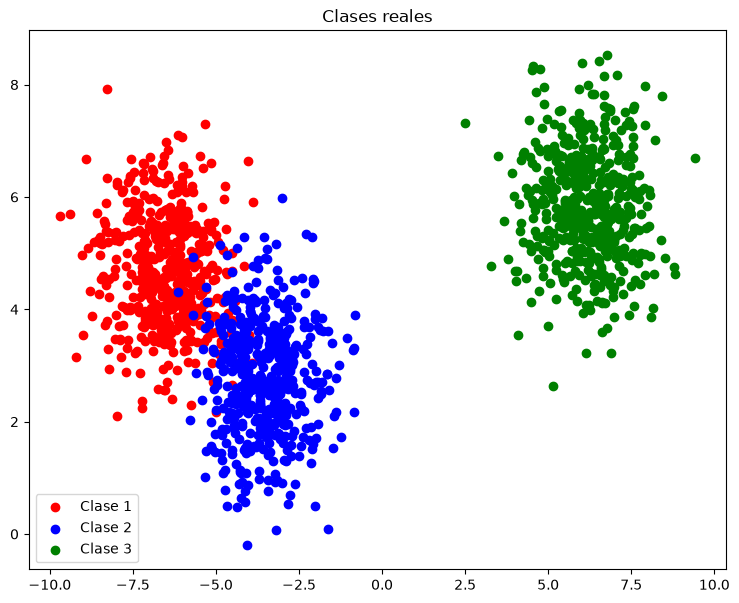

In [45]:
#visualizacion
colores = ['red', 'blue', 'green']
clases = ['Clase 1', 'Clase 2', 'Clase 3']

plt.figure(figsize=(9, 7))
plt.title('Clases reales')

for clase_id in np.unique(y):
    #solo los puntos que pertenecen a esta clase
    mascara = (y == clase_id)
    plt.scatter(X[mascara, 0], X[mascara, 1], color=colores[clase_id], label=clases[clase_id])

plt.legend()
plt.show()

# Implementación de K-means y Mean Shift

In [46]:
#k means
k_means = sklearn.cluster.KMeans(n_clusters = 3)
k_means.fit(X)

#mean shift
bandwidth = sklearn.cluster.estimate_bandwidth(X)
ms = sklearn.cluster.MeanShift(bandwidth = bandwidth)
ms.fit(X)


,"bandwidth bandwidth: float, default=NoneBandwidth used in the flat kernel.If not given, the bandwidth is estimated usingsklearn.cluster.estimate_bandwidth; see the documentation for thatfunction for hints on scalability (see also the Notes, below).",np.float64(2.5485414576310603)
,"seeds seeds: array-like of shape (n_samples, n_features), default=NoneSeeds used to initialize kernels. If not set,the seeds are calculated by clustering.get_bin_seedswith bandwidth as the grid size and default values forother parameters.",None
,"bin_seeding bin_seeding: bool, default=FalseIf true, initial kernel locations are not locations of allpoints, but rather the location of the discretized version ofpoints, where points are binned onto a grid whose coarsenesscorresponds to the bandwidth. Setting this option to True will speedup the algorithm because fewer seeds will be initialized.The default value is False.Ignored if seeds argument is not None.",False
,"min_bin_freq min_bin_freq: int, default=1To speed up the algorithm, accept only those bins with at leastmin_bin_freq points as seeds.",1
,"cluster_all cluster_all: bool, default=TrueIf true, then all points are clustered, even those orphans that arenot within any kernel. Orphans are assigned to the nearest kernel.If false, then orphans are given cluster label -1.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. The following tasks benefitfrom the parallelization:- The search of nearest neighbors for bandwidth estimation and label assignments. See the details in the docstring of the ``NearestNeighbors`` class.- Hill-climbing optimization for all seeds.See :term:`Glossary <n_jobs>` for more details.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"max_iter max_iter: int, default=300Maximum number of iterations, per seed point before the clusteringoperation terminates (for that seed point), if has not converged yet... versionadded:: 0.22",300
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers.","ndarray[float64](2, 2)","[[-4.51, 3.36], [ 6.15, 5.84]]"
"labels_ labels_: ndarray of shape (n_samples,)Labels of each point.","ndarray[int64](1500,)","[0,0,0,...,1,0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2


In [47]:
#labels y centroices
labels_kmeans = k_means.labels_
centros_kmeans = k_means.cluster_centers_

labels_ms = ms.labels_
centros_ms = ms.cluster_centers_

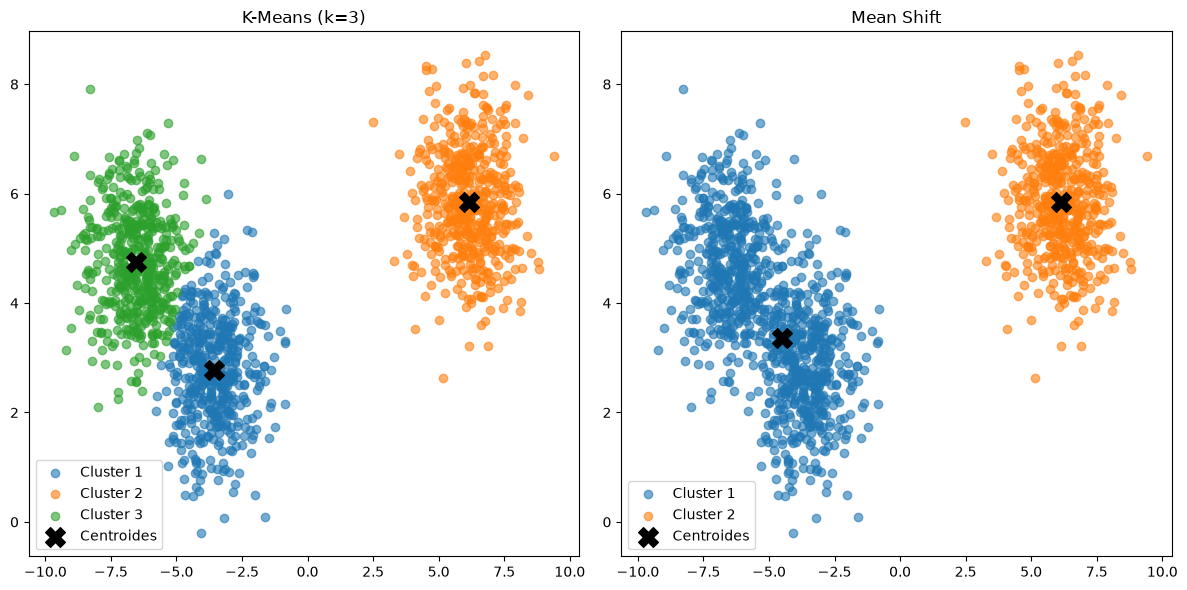

In [48]:
#visualizaciones

#listas de datos y títulos
labels = [labels_kmeans, labels_ms]
centros = [centros_kmeans, centros_ms]
titulos = ['K-Means (k=3)', 'Mean Shift']

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

#colores
cmap = plt.get_cmap('tab10')

for i in range(2):
    clusters_encontrados = np.unique(labels[i])

    for id in clusters_encontrados:
        mascara = (labels[i] == id)
        nombre_cluster = f'Cluster {id + 1}'

        axs[i].scatter(X[mascara, 0], X[mascara, 1], color=cmap(id), label=nombre_cluster, alpha=0.6)

    #centros
    axs[i].scatter(centros[i][:, 0], centros[i][:, 1], color='black', marker='X', s=200, label='Centroides')
    axs[i].set_title(titulos[i])
    axs[i].legend()

plt.tight_layout()
plt.show()

# Calculo de metricas de evaluación 
Homogeneidad, completitud y v-measure para kmeans y meanshift


In [49]:
hom_kmeans = sklearn.metrics.homogeneity_score(y, labels_kmeans)
com_kmeans = sklearn.metrics.completeness_score(y, labels_kmeans)
vmeasure_kmeans = sklearn.metrics.v_measure_score(y, labels_kmeans)


hom_ms = sklearn.metrics.homogeneity_score(y, labels_ms)
com_ms = sklearn.metrics.completeness_score(y, labels_ms)
vmeasure_ms = sklearn.metrics.v_measure_score(y, labels_ms)

In [52]:
import pandas as pd

resultados = {
    'Métrica': ['Homogeneidad', 'Completitud', 'V-Measure'],
    'K-Means': [hom_kmeans, com_kmeans, vmeasure_kmeans],
    'Mean Shift': [hom_ms, com_ms, vmeasure_ms]
}

# diccionario a dataframe
df_resultados = pd.DataFrame(resultados)

# tabla
display(df_resultados)

,Métrica,K-Means,Mean Shift
0,Homogeneidad,0.906418,0.57938
1,Completitud,0.906489,1.00000
2,V-Measure,0.906453,0.73368


In [53]:
# matriz de confusion para cada algoritmo 
A = sklearn.metrics.confusion_matrix(y, labels_kmeans)
B = sklearn.metrics.confusion_matrix(y, labels_ms)

print('Matriz de confusion para Kmeans')
print(A)
print('--'*35)
print('Matriz de confusion para Mean shift')
print(B)

Matriz de confusion para Kmeans
[[ 22   0 478]
 [486   0  14]
 [  0 500   0]]
----------------------------------------------------------------------
Matriz de confusion para Mean shift
[[500   0   0]
 [500   0   0]
 [  0 500   0]]


### Los modelos tuvieron resultados distintos para empezar, dado que de un inicio escogimos k means con K = 3, tuvo ventaja sobre meanshift y pudimos notar que si se cofundió con las dos nubes que estaban juntas.

## Homogeneidad
Podemos notar que k means tuvo mejor valor y tiene sentido para empezar porque hizo el mismo numero de clusteres que las clases que hay. Meanshift se confudió y por eso tiene 0.57 de homogeneidad pues cuando revisa el cluster azul nota que la mitad si pertenece a ese cluster pero la otra mitad no. por eso este valor cercano a 0.5 

## Completitud 
El caso de la completitud es intersante porque en meanshift tenemos un valor de *1* y esto debido a que cada clase se agrupó junta en un mismo cluster aunque en el cluster azul haya dos clases juntas (pero la completitud no detecta esto)

## V measure 
El v measure castiga a la mala homogeneidad de meanshift lo cual se nota con un valor de 0.73 y en cambio en kmeans se mantiene bastante alto.

## Matrices de confusión 
En las matrices podemos ver porque los valores de las homogeneidades y las completitudes. 
Nos indica cuantos valores asignó mal cada algoritmo segun la clase real y podemos ver porque la mala homogeneidad de meanshift asignando dos clases a un mismo cluster


# Efecto del numero de clusteres en las metricas 
Ahora ejecutaremos k-means con distintos valores de k para ver como se comportan las metricas con distintas cantidades de clusteres.

In [56]:
clusteres = [4, 6, 8, 10] #numero de clusteres
resultados = {'clusteres' : [4, 6, 8, 10],
            'Homogeneidad' : [],
            'Completitud' : [],
            'V-measure' : []
            }
for i, k in enumerate(clusteres):
    k_means = sklearn.cluster.KMeans(n_clusters = k)
    k_means.fit(X)

    labels = k_means.labels_
    centros = k_means.cluster_centers_

    resultados['Homogeneidad'].append(sklearn.metrics.homogeneity_score(y, labels))
    resultados['Completitud'].append(sklearn.metrics.completeness_score(y, labels))
    resultados['V-measure'].append(sklearn.metrics.v_measure_score(y, labels))

dt = pd.DataFrame(resultados)
display(dt)


,clusteres,Homogeneidad,Completitud,V-measure
0,4,0.906418,0.749904,0.820766
1,6,0.895672,0.573223,0.699055
2,8,0.907254,0.482993,0.630387
3,10,0.924717,0.444429,0.600332


### Podemos notar que mientras k aumenta las metricas tienen un comportamiento engañoso. Homogeneidad va aumentando pues mientras los clusteres se hacen más pequeños tienden a estar en la misma clase; la completitud va disminuyendo porque al haber cada vez más clusteres, las clases están cada vez más separadas. 
### Aqui es bueno recalcar porque consideramos V measure, pues nos evita confiar en estas metricas engañosas y es más fiel.


# Comparación en un dataset no separable 
Ahora probaremos datos no separables tan facilmente, en donde kmeans tiene problemas 

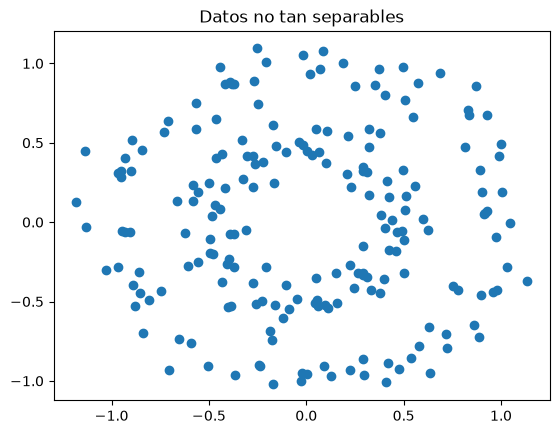

In [62]:
V, u = sklearn.datasets.make_circles(n_samples=200, noise=0.1, factor=0.5)
plt.figure()
plt.title('Datos no tan separables')
plt.scatter(V[:, 0], V[:, 1])
plt.show()


### K means (k=2) y meanshift aplicados a los nuevos datos

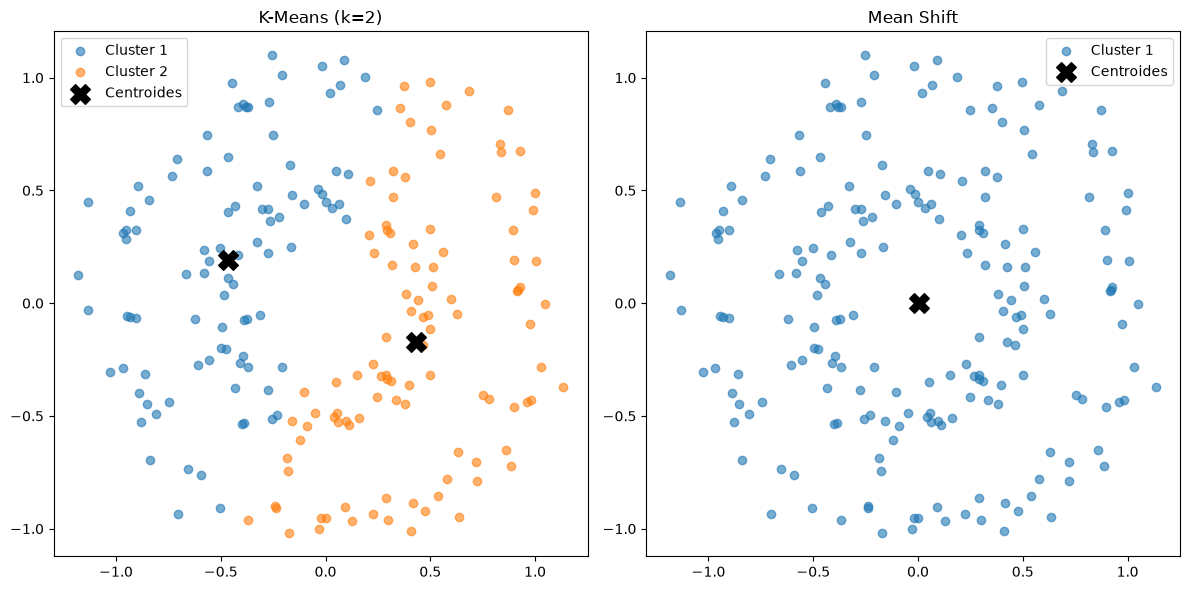

In [63]:
#k means con k = 2
k_means2 = sklearn.cluster.KMeans(n_clusters = 2)
k_means2.fit(V)

#mean shift
bandwidth2 = sklearn.cluster.estimate_bandwidth(V)
ms2 = sklearn.cluster.MeanShift(bandwidth = bandwidth)
ms2.fit(V)

#labels y centroices
labels_kmeans2 = k_means2.labels_
centros_kmeans2 = k_means2.cluster_centers_

labels_ms2 = ms2.labels_
centros_ms2 = ms2.cluster_centers_

#visualizaciones

#listas de datos y títulos
labels2 = [labels_kmeans2, labels_ms2]
centros2 = [centros_kmeans2, centros_ms2]
titulos2 = ['K-Means (k=2)', 'Mean Shift']

fig, axs = plt.subplots(1, 2, figsize=(12, 6))

#colores
cmap = plt.get_cmap('tab10')

for i in range(2):
    clusters_encontrados = np.unique(labels2[i])

    for id in clusters_encontrados:
        mascara = (labels2[i] == id)
        nombre_cluster = f'Cluster {id + 1}'

        axs[i].scatter(V[mascara, 0], V[mascara, 1], color=cmap(id), label=nombre_cluster, alpha=0.6)

    #centros
    axs[i].scatter(centros2[i][:, 0], centros2[i][:, 1], color='black', marker='X', s=200, label='Centroides')
    axs[i].set_title(titulos2[i])
    axs[i].legend()

plt.tight_layout()
plt.show()

In [65]:
hom_kmeans2 = sklearn.metrics.homogeneity_score(u, labels_kmeans2)
com_kmeans2 = sklearn.metrics.completeness_score(u, labels_kmeans2)
vmeasure_kmeans2 = sklearn.metrics.v_measure_score(u, labels_kmeans2)


hom_ms2 = sklearn.metrics.homogeneity_score(u, labels_ms2)
com_ms2 = sklearn.metrics.completeness_score(u, labels_ms2)
vmeasure_ms2 = sklearn.metrics.v_measure_score(u, labels_ms2)

resultados2 = {
    'Métrica': ['Homogeneidad', 'Completitud', 'V-Measure'],
    'K-Means (k=2)': [hom_kmeans2, com_kmeans2, vmeasure_kmeans2],
    'Mean Shift': [hom_ms2, com_ms2, vmeasure_ms2]
}

# diccionario a dataframe
df_resultados2 = pd.DataFrame(resultados2)

# tabla
display(df_resultados2)

,Métrica,K-Means (k=2),Mean Shift
0,Homogeneidad,0.000651,0.0
1,Completitud,0.000652,1.0
2,V-Measure,0.000652,0.0


### K means nos parte los datos de forma en la que no están distribuidos realmente obteniendo valores realmente malos para las metricas (lo que nos dice que está encontrando mal los clusteres).
### Mientras que Mean shift si logra encontrar mejor el unico cluster lo que se traduce en una completitud perfecta y por ende vmeasure 0.
